# Solving initial value problems numerically with SciPy

A first-order **initial value problem (IVP)** is
$$ y'(t) = f\big(t, y(t)\big), \qquad y(t_0) = y_0. $$

Most differential equations have **no formula** for the solution, for example $y' = t + \sin y$. But we can always compute the solution **numerically**: instead of a formula, we get a table of numbers
$$ t_0,\ t_1,\ t_2,\ \dots \qquad y_0,\ y_1,\ y_2,\ \dots \qquad \text{with } y_k \approx y(t_k). $$

The tool is `solve_ivp` from `scipy.integrate`.

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

## Part A. The basic call

We start with an equation whose exact solution we know, so we can check the numbers:
$$ y' + \tfrac12 y = \sin t, \qquad y(0) = 1, \qquad \text{exact: } y(t) = \tfrac25\sin t - \tfrac45\cos t + \tfrac95 e^{-t/2}. $$

### Step 1: write the equation as $y' = f(t, y)$

Solve for $y'$: $\quad y' = \sin t - \tfrac12 y$.

In Python, $f$ is a function of `t` and `y` (in this order!) that returns $y'$.

In [31]:
def f(t, y):
    return np.sin(t) - y/2

def y_exact(t):                 # only used to check the numerical answer
    return 2/5*np.sin(t) - 4/5*np.cos(t) + 9/5*np.exp(-t/2)

### Step 2: call `solve_ivp`

```python
sol = solve_ivp(f, (t0, T), [y0])
```
- `f`: the right side $f(t, y)$.
- `(t0, T)`: the time interval $[t_0, T]$.
- `[y0]`: the initial value, **in a list**.

In [32]:
sol = solve_ivp(f, (0, 10), [1])
print("success:", sol.success)
print("sol.t =", np.round(sol.t, 2))
print("sol.y =", np.round(sol.y, 3))

success: True
sol.t = [ 0.    0.1   1.05  2.48  4.06  5.54  7.03  8.64 10.  ]
sol.y = [[ 1.     0.958  1.015  1.398  0.408 -0.748 -0.261  0.873  0.466]]


The result `sol` contains:
- `sol.success`: `True` if the solver reached $t = T$.
- `sol.t`: the times $t_k$. The solver **chooses the steps itself**: they are not equally spaced.
- `sol.y`: the values $y_k$. It is a 2D array with **one row**, so the numbers are in `sol.y[0]`.

### Step 3: plot the solution

Only 9 points: too few for a smooth curve. With `t_eval=tt` the solver reports the solution at the times we choose.

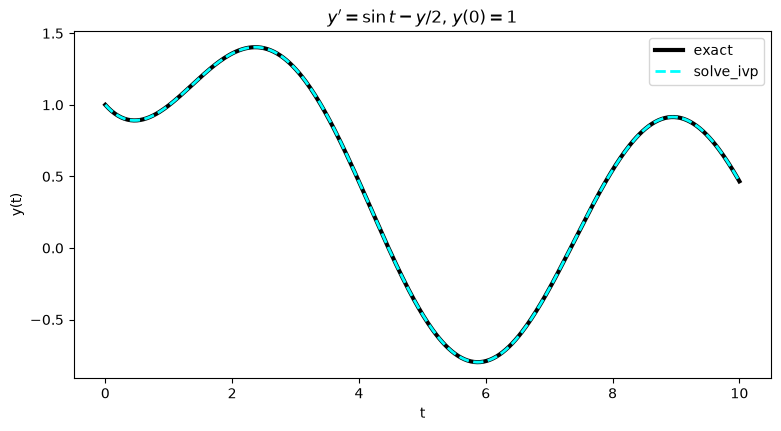

In [33]:
tt = np.linspace(0, 10, 400)
sol = solve_ivp(f, (0, 10), [1], t_eval=tt)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(tt, y_exact(tt), "k", lw=3, label="exact")
ax.plot(sol.t, sol.y[0], "--", color="cyan", lw=2, label="solve_ivp")
ax.set_xlabel("t"); ax.set_ylabel("y(t)")
ax.set_title(r"$y' = \sin t - y/2$, $y(0) = 1$")
ax.legend()
plt.show()

### Step 4: how large is the error?

In [34]:
err = np.max(np.abs(sol.y[0] - y_exact(tt)))
print("max error:", err)

max error: 0.0007428953537668148


The curves look identical, but the error is about $10^{-3}$: only 2–3 correct digits. The default settings are **rough**.

## Part B. Accuracy: `rtol` and `atol`

### What the solver does in each step

In every step the solver makes an **estimate of its own error**. It accepts the step only if
$$ |\text{error}| \;\le\; \texttt{atol} + \texttt{rtol}\cdot|y|. $$
Otherwise it repeats the step with a smaller step size.

- `rtol` = **relative tolerance**: the error allowed *as a fraction of $y$*. `rtol=1e-6` means roughly **6 correct significant digits**. Default: `1e-3`.
- `atol` = **absolute tolerance**: the error allowed *in absolute terms*. It matters when $y$ is **close to 0**, where $\texttt{rtol}\cdot|y|$ is almost 0. Default: `1e-6`.

The bigger of the two terms wins: when $|y|$ is large, `rtol` controls the accuracy; when $|y|$ is small, `atol` does.

**Rule of thumb:** choose `rtol` for the digits you want, and `atol` smaller than the size of $y$ that you still care about.

### Smaller tolerances, smaller errors

In [35]:
print("   rtol      max error   calls of f")
for rtol in [1e-3, 1e-6, 1e-9]:
    sol = solve_ivp(f, (0, 10), [1], t_eval=tt, rtol=rtol, atol=1e-12)
    err = np.max(np.abs(sol.y[0] - y_exact(tt)))
    print(f"{rtol:8.0e}   {err:9.1e}   {sol.nfev:5d}")

   rtol      max error   calls of f
   1e-03     7.4e-04      56
   1e-06     2.7e-06     176
   1e-09     1.6e-08     560


- The error follows `rtol`: each time we ask for 3 more digits, we get 2 to 3 more.
- `sol.nfev` counts how many times the solver called `f`. More accuracy costs more work, but not much.

(The real error can be a bit larger than `rtol`: the tolerance controls each step, and errors from many steps add up.)



## Part C. An equation with no formula

$$ y' = t + \sin y, \qquad y(0) = 0. $$
There is no formula for this solution, but for `solve_ivp` it is just another `f`.

### Step 1: solve and plot

We also solve for several other initial values $y(0) = y_0$: same equation, different starting points.

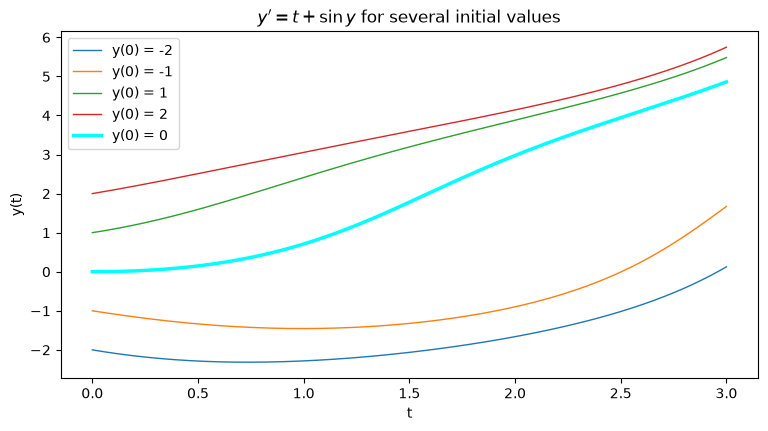

In [37]:
def g(t, y):
    return t + np.sin(y)

tt = np.linspace(0, 3, 300)
fig, ax = plt.subplots(figsize=(9, 4.5))
for y0 in [-2, -1, 1, 2]:
    sol = solve_ivp(g, (0, 3), [y0], t_eval=tt, rtol=1e-8, atol=1e-10)
    ax.plot(sol.t, sol.y[0], lw=1, label=f"y(0) = {y0}")
sol = solve_ivp(g, (0, 3), [0], t_eval=tt, rtol=1e-8, atol=1e-10)
ax.plot(sol.t, sol.y[0], color="cyan", lw=2.5, label="y(0) = 0")
ax.set_xlabel("t"); ax.set_ylabel("y(t)")
ax.set_title(r"$y' = t + \sin y$ for several initial values")
ax.legend()
plt.show()

### Step 2: check the answer without an exact solution

**Always check.** Without a formula we cannot compute the error directly. Instead: solve again with **tighter tolerances**. The digits that do not change are reliable.

`sol.y[0, -1]` is the last value, i.e. $y(3)$.

In [38]:
for rtol in [1e-4, 1e-7, 1e-10]:
    sol = solve_ivp(g, (0, 3), [0], rtol=rtol, atol=1e-12)
    print(f"rtol = {rtol:.0e}:   y(3) = {sol.y[0, -1]:.10f}")

rtol = 1e-04:   y(3) = 4.8594731540
rtol = 1e-07:   y(3) = 4.8594856198
rtol = 1e-10:   y(3) = 4.8594856793


Going from `rtol=1e-7` to `rtol=1e-10` does not change the first 7 digits: $y(3) \approx 4.859486$.



## Part D. When the solution blows up: stop with an event

Some solutions go to infinity in **finite time**. Example:
$$ y' = y^2, \qquad y(0) = 1, \qquad \text{exact: } y(t) = \frac{1}{1 - t}. $$
As $t \to 1$, $y(t) \to \infty$: the solution does not exist beyond $t = 1$.

### Step 1: what `solve_ivp` does

In [41]:
def h(t, y):
    return y**2

sol = solve_ivp(h, (0, 2), [1])
print("success:", sol.success)
print("message:", sol.message)
print("last t :", sol.t[-1])
print("last y :", sol.y[0, -1])

success: False
message: Required step size is less than spacing between numbers.
last t : 0.9999286400563747
last y : 488643792459026.6


The solver takes smaller and smaller steps near $t = 1$, until the step is too small for the computer's numbers. Then it **gives up** (`success: False`), with a huge last value $y \approx 5\cdot 10^{14}$.

### Step 2: stop on purpose with an event

An **event** is a function `event(t, y)`. The solver watches it during the computation, and the event **occurs** when this function **crosses zero**.

To stop when $y$ reaches $10^6$:
- the event function is $y - 10^6$ (it is zero exactly when $y = 10^6$);
- `too_big.terminal = True` means: **stop** the solver when the event occurs;
- pass it with `events=too_big`.

Inside the event function, `y` is an array: the value is `y[0]`.

In [42]:
def too_big(t, y):
    return y[0] - 1e6

too_big.terminal = True

sol = solve_ivp(h, (0, 2), [1], events=too_big, rtol=1e-10, atol=1e-12)
print("status :", sol.status, "  (1 = stopped by an event)")
print("message:", sol.message)
print("event at t =", sol.t_events[0])
print("y there    =", sol.y_events[0])


status : 1   (1 = stopped by an event)
message: A termination event occurred.
event at t = [0.999999]
y there    = [[999999.99998178]]


- `sol.status == 1`: the solver stopped **because of the event**, not because it failed.
- `sol.t_events[0]`: the times when the event occurred; `sol.y_events[0]`: the values of $y$ there.
- The event time $t = 0.999999$ is where $1/(1-t) = 10^6$: the event also tells us **where** the blow-up happens.

### Step 3: plot up to the event

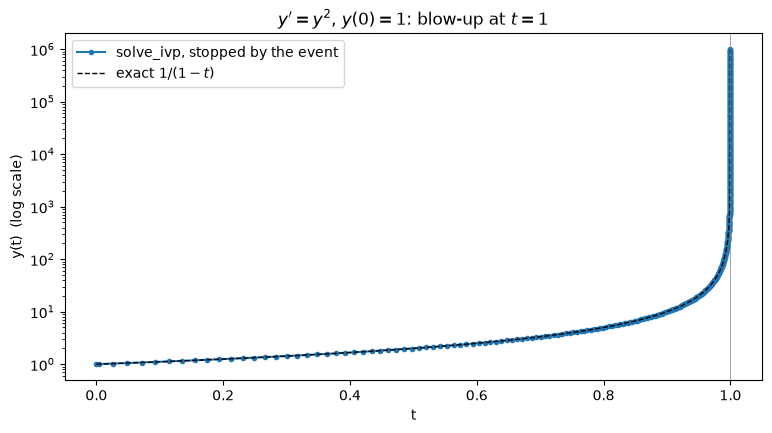

In [43]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.semilogy(sol.t, sol.y[0], "o-", ms=3, label="solve_ivp, stopped by the event")
ax.semilogy(sol.t, 1/(1 - sol.t), "k--", lw=1, label=r"exact $1/(1-t)$")
ax.axvline(1, color="gray", lw=0.5)
ax.set_xlabel("t"); ax.set_ylabel("y(t)  (log scale)")
ax.set_title(r"$y' = y^2$, $y(0) = 1$: blow-up at $t = 1$")
ax.legend()
plt.show()

The points crowd together near $t = 1$: the solver takes smaller and smaller steps as $y$ grows.

## Summary

| task | call |
|---|---|
| right side $y' = f(t, y)$ | `def f(t, y): return ...` |
| solve | `sol = solve_ivp(f, (t0, T), [y0])` |
| output at chosen times | `t_eval=np.linspace(t0, T, 400)` |
| accuracy | `rtol=1e-8, atol=1e-10` |
| results | `sol.t` (times), `sol.y[0]` (values), `sol.y[0, -1]` (last value) |
| did it work? | `sol.success`, `sol.message` |
| stop when $y = c$ | `def ev(t, y): return y[0] - c`, `ev.terminal = True`, `events=ev` |
| event results | `sol.status` (1 = event), `sol.t_events[0]`, `sol.y_events[0]` |

- `rtol` controls the **number of correct digits**; `atol` controls the error when $y$ is **near 0**. The defaults (`1e-3`, `1e-6`) are rough.
- **Check** with an exact solution if there is one; otherwise **tighten the tolerances** and see which digits stay.
- If the solution **blows up**, the solver fails near the blow-up time; a terminal **event** stops it cleanly at a chosen large value.

## Exercises

**Syntax**

| task | call |
|---|---|
| right side | `def f(t, y): return ...` |
| solve | `sol = solve_ivp(f, (t0, T), [y0], t_eval=tt, rtol=1e-8, atol=1e-10)` |
| results | `sol.t`, `sol.y[0]`, last value `sol.y[0, -1]` |
| all but the last point | `sol.t[:-1]`, `sol.y[0, :-1]` |
| event | `def ev(t, y): return y[0] - 1e6`<br>`ev.terminal = True`<br>`sol = solve_ivp(f, (t0, T), [y0], events=ev)`<br>`sol.t_events[0]` |
| error | `np.max(np.abs(sol.y[0] - y_exact(sol.t)))` |
| plot | `tt = np.linspace(0, 10, 400)`<br>`fig, ax = plt.subplots(figsize=(9, 4.5))`<br>`ax.plot(sol.t, sol.y[0], label="y(t)")`<br>`ax.set_xlabel("t"); ax.legend()`<br>`plt.show()` |

**Exercise 1.** The logistic equation
$$ y' = y\,(1 - y), \qquad y(0) = \tfrac{1}{10}, \qquad \text{exact: } y(t) = \frac{1}{1 + 9e^{-t}}. $$

(a) Solve on $[0, 10]$ with `solve_ivp` (default tolerances). Plot the numerical and the exact solution, and compute the maximum error.

(b) Repeat with `rtol = 1e-6` and `rtol = 1e-9` (and `atol=1e-12`). How does the error change? How does `sol.nfev` change?

(c) Plot the solutions for $y(0) = 0.1,\ 0.5,\ 1.5$ on $[0, 10]$. What do they all approach?

In [44]:
# Exercise 1

**Exercise 2.** An equation with no formula:
$$ y' = \cos(t\,y), \qquad y(0) = 1. $$

(a) Solve on $[0, 10]$ and plot $y(t)$.

(b) Find $y(10)$ with `rtol = 1e-4, 1e-7, 1e-10` (and `atol=1e-12`). How many digits of $y(10)$ can you trust?

In [45]:
# Exercise 2

**Exercise 3.** Another solution that blows up:
$$ y' = 1 + y^2, \qquad y(0) = 0, \qquad \text{exact: } y(t) = \tan t. $$

(a) Try to solve on $[0, 3]$. Print `sol.success`, `sol.message`, and the last time `sol.t[-1]` the solver reached.

(b) Plot the numerical solution **without the last point** (`sol.t[:-1]`, `sol.y[0, :-1]`), together with the exact solution at the same times. Then plot again with `ax.semilogy` instead of `ax.plot`. How large does $y$ get?

(c) Explain with the exact solution why the solver cannot get past this time.

(d) Use a terminal event to stop the solver when $y = 10^6$ (with `rtol=1e-10, atol=1e-12`). At which time does it stop? Compare with $\pi/2$.

In [46]:
# Exercise 3
